# Imports

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from pathlib import Path

from helpers.preprocessing import (load_qc_table, save_qc_entry, detect_bad_channels, detect_bad_spans,
                                   set_bad_spans, get_bad_spans, filter_raw, interpolate_and_reference,
                                   preprocess_all, HIGH_BAD_THRESHOLD, TARGET_FS)

In [13]:
data_dir = Path('C:/Users/eva/Documents/Master/ICM/Ilo/EEG')
QC_CSV = Path('C:/Users/eva/Documents/Master/ICM/Ilo/GLHMM/bad_segments_channels.csv')  # one row per EDF file: bad_segment, bad_channels

# Every channel is typed 'eeg' in the EDF header, so the non-EEG ones are retyped by name
CHANNEL_TYPES = {'IO': 'eog', 'EMG': 'emg', 'ECG': 'ecg', 'Respi': 'resp',
                 'L_IndexMid': 'misc', 'L_RingPink': 'misc', 'L_Thumb': 'misc', 'R_RingPink': 'misc', 'R_Thumb': 'misc',
                 'Left Index+Middl': 'misc', 'Left Ring+Pinky': 'misc', 'Left Thumb': 'misc',
                 'Right Ring+Pinky': 'misc', 'Right Thumb': 'misc'}

FILE = 'TT009.edf'


# Load data
One `EEG/<subject>_filtered.edf` per recording (~3h, 500 Hz, 62 EEG channels + physiological channels). Despite the name, the EEG channels in these files are identical to the unfiltered `<subject>.edf`: only the amplifier band (0.01 or DC to 250 Hz) has been applied, so the 50 Hz notch and band-pass still have to be done here.

In [14]:
def load_filtered_edf(path, preload=False):
    """Read one *_filtered.edf with correct channel types and standard 10-20 electrode positions."""
    raw = mne.io.read_raw_edf(path, preload=preload, verbose=False)
    raw.set_channel_types({ch: t for ch, t in CHANNEL_TYPES.items() if ch in raw.ch_names}, verbose=False)
    raw.set_montage('standard_1020', verbose=False)
    return raw


edf_files = sorted(data_dir.glob('*.edf'))
# Lazy loading: only the headers are read here, call raws[name].load_data() to get the samples in memory
raws = {f.name: load_filtered_edf(f) for f in edf_files}
qc_table = load_qc_table(QC_CSV)  # bad segments / bad channels, keyed by EDF file name

pd.DataFrame([{'file': name,
               'subject': name.split('_')[0],
               'n_eeg': len(mne.pick_types(raw.info, eeg=True)),
               'n_other': len(raw.ch_names) - len(mne.pick_types(raw.info, eeg=True)),
               'sfreq': raw.info['sfreq'],
               'duration_min': round(raw.times[-1] / 60, 1),
               'highpass': raw.info['highpass'],
               'lowpass': raw.info['lowpass'],
               'in_qc_table': name in qc_table} for name, raw in raws.items()])

C:\Users\eva\AppData\Local\Temp\ipykernel_15152\3459650855.py:4: RuntimeWarning: The unit for channel(s) L_IndexMid, L_RingPink, L_Thumb, R_RingPink, R_Thumb has changed from V to NA.
  raw.set_channel_types({ch: t for ch, t in CHANNEL_TYPES.items() if ch in raw.ch_names}, verbose=False)
C:\Users\eva\AppData\Local\Temp\ipykernel_15152\3459650855.py:5: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  raw.set_montage('standard_1020', verbose=False)
C:\Users\eva\AppData\Local\Temp\ipykernel_15152\3459650855.py:4: RuntimeWarning: The unit for channel(s) L_IndexMid, L_RingPink, L_Thumb, R_RingPink, R_Thumb has changed from V to NA.
  raw.set_channel_types({ch: t for ch, t in CHANNEL_TYPES.items() if ch in raw.ch_names}, verbose=False)
C:\Users\eva\AppData\Local\Temp\ipykernel_15152\3459650855.py:5: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  ra

,file,subject,n_eeg,n_other,sfreq,duration_min,highpass,lowpass,in_qc_table
0,TT001.edf,TT001.edf,62,8,500.0,202.5,0.01,250.0,False
1,TT002.edf,TT002.edf,62,8,500.0,170.8,0.01,250.0,False
2,TT003.edf,TT003.edf,62,9,500.0,183.9,0.00,250.0,False
3,TT004.edf,TT004.edf,62,9,500.0,186.9,0.00,250.0,False
4,TT005.edf,TT005.edf,62,9,500.0,207.2,0.00,250.0,True
5,TT006.edf,TT006.edf,62,9,500.0,165.1,0.00,250.0,False
6,TT007.edf,TT007.edf,62,9,500.0,175.2,0.00,250.0,False
7,TT008.edf,TT008.edf,62,9,500.0,208.8,0.00,250.0,False
8,TT009.edf,TT009.edf,62,9,500.0,163.9,0.00,250.0,False
9,TT009_part2.edf,TT009,62,9,500.0,22.0,0.00,250.0,False


In [15]:
raw = raws[FILE]
full_raw = raw.copy().load_data()  # load all samples into memory
# Filter and downsample first, re-reference later: before the average reference a bad channel only affects itself
filter_raw(full_raw)  # 50 Hz notch + 1-40 Hz band-pass
full_raw.resample(TARGET_FS, verbose=False)  # after the 40 Hz low-pass, so nothing aliases
full_raw

Reading 0 ... 4917999  =      0.000 ...  9835.998 secs...


<RawEDF | TT009.edf, 71 x 983600 (9836.0 s), ~532.9 MiB, data loaded>

# Bad channels and bad recordings
Bad channels are proposed automatically, reviewed by eye in the MNE browser, then saved to `bad_segments_channels.csv`. A recording is flagged `bad_segment` (skipped entirely by the GLHMM notebook) when more than 30% of its EEG channels are bad.

TT009.edf: automatic proposal ['C5', 'PO8'], already in bad_segments_channels.csv []


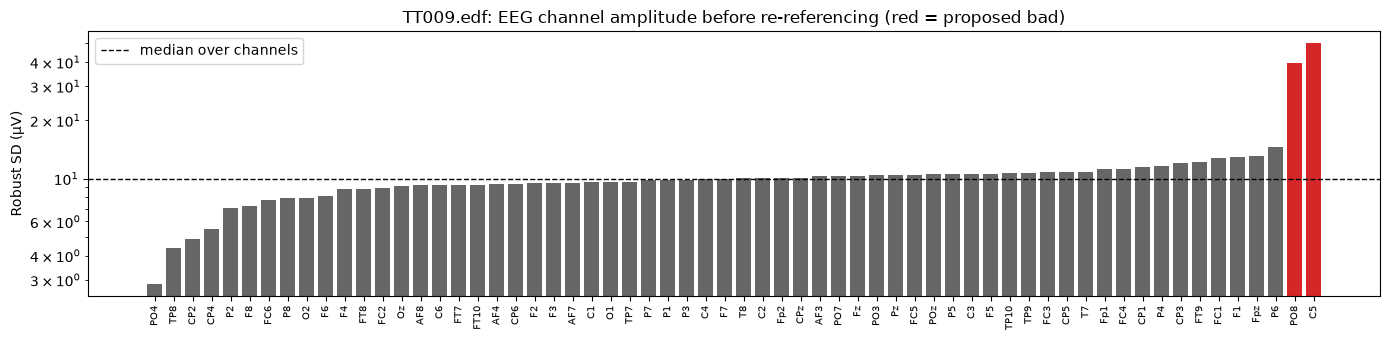

In [16]:
# Automatic proposal: EEG channels whose robust SD is > 3x the median over channels, or flat (< 0.1 µV)
auto_bads, robust_sd = detect_bad_channels(full_raw, 3, 1)
saved_bads = qc_table.get(FILE, {}).get('bad_channels', [])  # from a previous review of this file
proposed_bads = sorted(set(auto_bads) | set(saved_bads))
print(f'{FILE}: automatic proposal {auto_bads}, already in {QC_CSV.name} {saved_bads}')

sd_sorted = robust_sd.sort_values()
fig_sd, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(np.arange(len(sd_sorted)), sd_sorted.values, color=['C3' if ch in proposed_bads else '0.4' for ch in sd_sorted.index])
ax.axhline(robust_sd.median(), color='k', lw=1, ls='--', label='median over channels')
ax.set_xticks(np.arange(len(sd_sorted)), sd_sorted.index, rotation=90, fontsize=7)
ax.set_ylabel('Robust SD (µV)')
ax.set_yscale('log')
ax.set_title(f'{FILE}: EEG channel amplitude before re-referencing (red = proposed bad)')
ax.legend()
fig_sd.tight_layout()

In [17]:
# Review by eye: the proposed channels are pre-marked (grey). Click a channel trace or name to mark/unmark it, close the window when done.
%matplotlib tk
full_raw.info['bads'] = list(proposed_bads)
full_raw.plot(n_channels=31, duration=30, scalings='auto', title=FILE, block=True)
%matplotlib inline

eeg_names = [full_raw.ch_names[i] for i in mne.pick_types(full_raw.info, eeg=True, exclude=[])]
bad_channels = [ch for ch in eeg_names if ch in full_raw.info['bads']]
bad_fraction = len(bad_channels) / len(eeg_names)
# The whole recording is discarded when too many channels are bad, or when it was already flagged in the CSV
bad_segment = bool(bad_fraction > HIGH_BAD_THRESHOLD or qc_table.get(FILE, {}).get('bad_segment', False))
print(f'{FILE}: {len(bad_channels)} bad channel(s) ({bad_fraction:.0%}) {bad_channels}, bad_segment = {bad_segment}')

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Channels marked as bad:
['C5', 'PO8']
TT009.edf: 2 bad channel(s) (3%) ['C5', 'PO8'], bad_segment = False


# ICA to remove ocular and cardiac artifacts

In [18]:
from helpers.preprocessing import fit_ica, load_ica, ICA_SUFFIX, REFERENCE

path_ica = data_dir / FILE.replace('.edf', ICA_SUFFIX)
full_raw.info['bads'] = bad_channels
full_raw.set_eeg_reference(REFERENCE, projection=False, verbose=False)  # over the good channels only
saved_spans = qc_table.get(FILE, {}).get('bad_spans')
set_bad_spans(full_raw, saved_spans if saved_spans is not None else detect_bad_spans(full_raw))

ica = load_ica(path_ica, full_raw, bad_channels)
if ica is None:
    ica = fit_ica(full_raw, bad_channels)
print(f'{FILE}: proposed components {ica.exclude} {ica.labels_}')

# Review by eye: click a component name to exclude/keep it, close the window when done
%matplotlib tk
ica.plot_components()
ica.plot_sources(full_raw, block=True)
%matplotlib inline

ica.save(path_ica, overwrite=True)
ica.apply(full_raw)

Use rng= instead of random_state= in new code
TT009.edf: proposed components [2, 16] {'eog/0/IO': [np.int64(2), np.int64(16)], 'eog': [np.int64(16), np.int64(2)], 'ecg': [], 'ecg/ECG-MAG': []}
Creating RawArray with float64 data, n_channels=32, n_times=983600
    Range : 0 ... 983599 =      0.000 ...  9835.990 secs
Ready.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Writing ICA solution to C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT009_ica.fif...
Applying ICA to Raw instance
    Transforming to ICA space (30 components)
    Zeroing out 2 ICA components
    Projecting back using 60 PCA components


<RawEDF | TT009.edf, 71 x 983600 (9836.0 s), ~532.9 MiB, data loaded>

In [19]:
# Save the reviewed result (edit bad_channels / bad_segment by hand here first if needed)
save_qc_entry(QC_CSV, FILE, bad_channels, bad_segment)
qc_table = load_qc_table(QC_CSV)
print(f'Saved to {QC_CSV.name}: {qc_table[FILE]}')

Saved to bad_segments_channels.csv: {'bad_segment': False, 'bad_channels': ['C5', 'PO8'], 'bad_spans': None}


# Interpolate, re-reference and quality control
The bad channels are interpolated from their neighbours, then the average reference is applied. The result is summarised in an `mne.Report` (HTML file in `outputs/`): recording info, butterfly plots of 10 short segments, power spectrum, and the channel amplitude plot from above.

In [20]:
filtered = interpolate_and_reference(full_raw, bad_channels)  # in place: full_raw is now the preprocessed recording
filtered

<RawEDF | TT009.edf, 71 x 983600 (9836.0 s), ~532.9 MiB, data loaded>

In [21]:
# Bad time spans: saved ones if this file was already reviewed, otherwise the automatic proposal
# (more than 10% of the EEG channels beyond +-250 µV, with 1 s of margin on each side)
saved_spans = qc_table.get(FILE, {}).get('bad_spans')
set_bad_spans(filtered, saved_spans if saved_spans is not None else detect_bad_spans(filtered))

# Review by eye: spans are shown as coloured bands. Press 'a' to enter annotation mode, then drag to add a span
# (label BAD_segment), drag its edges to resize it, right-click to delete it. Close the window when done.
%matplotlib tk
filtered.plot(n_channels=31, duration=60, scalings='auto', title=FILE, block=True)
%matplotlib inline

bad_spans = get_bad_spans(filtered)
set_bad_spans(filtered, bad_spans)  # same label for the spans drawn by hand
bad_s = sum(b - a for a, b in bad_spans)
print(f'{FILE}: {len(bad_spans)} bad span(s), {bad_s:.0f} s ({bad_s / filtered.times[-1]:.1%} of the recording)')

save_qc_entry(QC_CSV, FILE, bad_channels, bad_segment, bad_spans)
qc_table = load_qc_table(QC_CSV)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Channels marked as bad:
[np.str_('L_IndexMid')]
TT009.edf: 4 bad span(s), 9 s (0.1% of the recording)


In [22]:
report_path = Path('C:/Users/eva/Documents/Master/ICM/Ilo/GLHMM/outputs') / f"{FILE.replace('.edf', '')}_qc_report.html"

report = mne.Report(title=f'{FILE} quality control', verbose=False)
report.add_raw(filtered, title=f'Preprocessed, {TARGET_FS} Hz', psd=True, butterfly=True)
report.add_figure(fig_sd, title='EEG channel amplitude',
                  caption=f'Robust SD of each EEG channel before re-referencing. Interpolated: {bad_channels}. bad_segment = {bad_segment}.')
report.save(report_path, overwrite=True, open_browser=False)
print(f'Report saved to: {report_path}')

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Setting 978 of 983600 (0.10%) samples to NaN, retaining 982622 (99.90%) samples.
Effective window size : 20.480 (s)
At least one good data span is shorter than n_per_seg, and will be analyzed with a shorter window than the rest of the file.
Plotting power spectral density (dB=True).
Saving report to : C:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\outputs\TT009_qc_report.html
Report saved to: C:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\outputs\TT009_qc_report.html


# Preprocess and save all recordings
Applies the pipeline to every `EEG/*_filtered.edf` using `bad_segments_channels.csv` and saves `EEG/<name>_preproc_raw.fif` (100 Hz, bad channels interpolated, average reference, bad spans stored as `BAD_segment` annotations). These files are what `ghmm_full_EEG.ipynb` loads.
- Recordings flagged `bad_segment` are skipped.
- Files whose `bad_spans` cell is empty get their spans detected automatically, and written to the CSV. Clear the cell to detect them again.

Rerun this cell whenever the CSV changes (same as running `python helpers/preprocessing.py`).

In [24]:
preprocess_all(data_dir, QC_CSV)

Found 22 recording(s) in C:\Users\eva\Documents\Master\ICM\Ilo\EEG



c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:115: RuntimeWarning: The unit for channel(s) L_IndexMid, L_RingPink, L_Thumb, R_RingPink, R_Thumb has changed from V to NA.
  
c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:116: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  
c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:301: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT001_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  """Interpolate bad channels, re-reference, notch and band-pass a preloaded Raw in place."""
c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:301: RuntimeWarning: Acquisition skips detected

TT001.edf -> TT001_preprocessed.fif: 0 channel(s) interpolated, ICA component(s) [np.int32(1), np.int32(2)] removed (from TT001_ica.fif), 4 bad span(s) = 9 s (0.1%, from the QC table)


c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:115: RuntimeWarning: The unit for channel(s) L_IndexMid, L_RingPink, L_Thumb, R_RingPink, R_Thumb has changed from V to NA.
  
c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:116: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  
c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:301: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT002_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  """Interpolate bad channels, re-reference, notch and band-pass a preloaded Raw in place."""
c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:301: RuntimeWarning: Acquisition skips detected

TT002.edf -> TT002_preprocessed.fif: 0 channel(s) interpolated, ICA component(s) [np.int32(0), np.int32(1)] removed (from TT002_ica.fif), 0 bad span(s) = 0 s (0.0%, from the QC table)


...

TT018.edf -> TT018_preprocessed.fif: 0 channel(s) interpolated, ICA component(s) [] removed (detected automatically), 497 bad span(s) = 3522 s (29.7%, detected automatically)


c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:115: RuntimeWarning: The unit for channel(s) L_IndexMid, L_RingPink, L_Thumb, R_RingPink, R_Thumb has changed from V to NA.
  
c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:116: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  


Use rng= instead of random_state= in new code


c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:301: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT019_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  """Interpolate bad channels, re-reference, notch and band-pass a preloaded Raw in place."""
c:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\helpers\preprocessing.py:301: RuntimeWarning: Acquisition skips detected but did not fit evenly into output buffer_size, will be written as zeroes.
  """Interpolate bad channels, re-reference, notch and band-pass a preloaded Raw in place."""


TT019.edf -> TT019_preprocessed.fif: 0 channel(s) interpolated, ICA component(s) [0, 3] removed (detected automatically), 5 bad span(s) = 15 s (0.1%, detected automatically)


# Visualize one preprocessed subject


In [27]:
preproc_path = data_dir / FILE.replace('.edf', '_preprocessed.fif')
preproc = mne.io.read_raw_fif(preproc_path, preload=False, verbose=False)

print(preproc)
print(f'Duration: {preproc.times[-1] / 60:.1f} minutes')
print(f'Bad spans: {len(preproc.annotations)}')

%matplotlib tk
preproc.plot(
    n_channels=31,
    duration=60,
    scalings='auto',
    title=f'Preprocessed {FILE}',
    block=True,
)
%matplotlib inline

C:\Users\eva\AppData\Local\Temp\ipykernel_15152\10167665.py:2: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT009_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  preproc = mne.io.read_raw_fif(preproc_path, preload=False, verbose=False)


<Raw | TT009_preprocessed.fif, 71 x 983600 (9836.0 s), ~85 KiB, data not loaded>
Duration: 163.9 minutes
Bad spans: 226
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Channels marked as bad:
none
